In [21]:
from sklearn.datasets import load_wine
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold
import matplotlib.ticker as mticker
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support



In [22]:
wine_df = load_wine(as_frame=True).frame
print(wine_df.shape, wine_df['target'].value_counts())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X = wine_df[["alcohol", "malic_acid"]]
y = wine_df["target"]

wine_df.head()



(178, 14) target
1    71
0    59
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


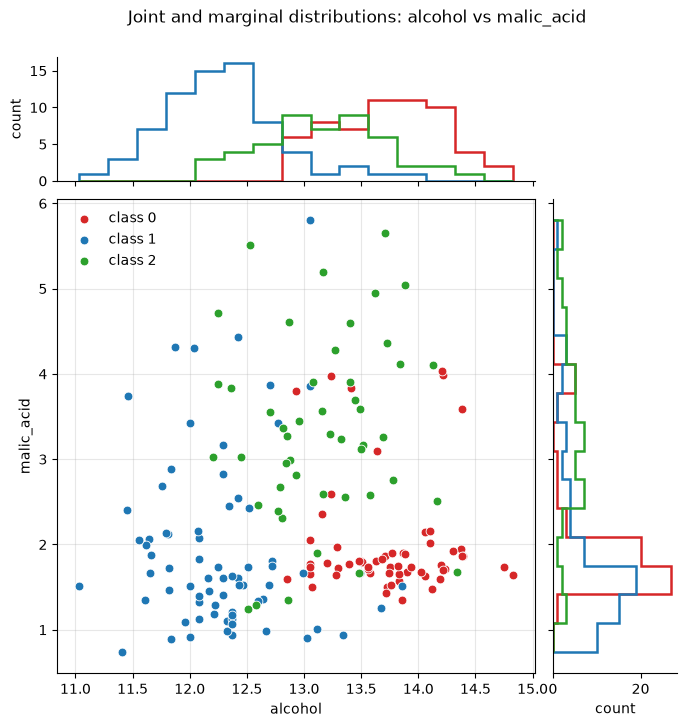

In [23]:
# Step 3: joint distribution with marginal distributions on the edges
classes = [0, 1, 2]
colors = ['tab:red', 'tab:blue', 'tab:green']

fig = plt.figure(figsize=(8, 8))
gs = fig.add_gridspec(2, 2, width_ratios=(5, 1.3), height_ratios=(1.3, 5),
                      hspace=0.06, wspace=0.06)
ax = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

bins_x = np.linspace(wine_df['alcohol'].min(), wine_df['alcohol'].max(), 16)
bins_y = np.linspace(wine_df['malic_acid'].min(), wine_df['malic_acid'].max(), 16)

for c, col in zip(classes, colors):
    d = wine_df[wine_df['target'] == c]
    # 2D joint distribution
    ax.scatter(d['alcohol'], d['malic_acid'], c=col, s=40,
               edgecolor='white', linewidth=0.6, label=f'class {c}')
    # marginal distributions
    ax_top.hist(d['alcohol'], bins=bins_x, histtype='step', lw=1.8, color=col)
    ax_right.hist(d['malic_acid'], bins=bins_y, histtype='step', lw=1.8,
                  color=col, orientation='horizontal')

ax.set_xlabel('alcohol')
ax.set_ylabel('malic_acid')
ax.legend(frameon=False, loc='upper left')
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

ax_top.tick_params(labelbottom=False)
ax_right.tick_params(labelleft=False)
ax_top.set_ylabel('count')
ax_right.set_xlabel('count')
for a in (ax_top, ax_right):
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.suptitle('Joint and marginal distributions: alcohol vs malic_acid', y=0.94)
plt.show()

### Step 4: Assumptions
My main assumption is that the two features are complementary. Each one separates the pair that the other one confuses. In the scatter plot the three classes sit in different areas: class 0 at the bottom right (high alcohol, low malic acid), class 1 at the bottom left (low alcohol, low malic acid), and class 2 in the upper band (high malic acid). The clusters look fairly compact , so distance  based models like SVM and k-NN should be suitable here.The plot also shows that the data is mostly, but not perfectly, linearly separable. 



## Step 5: Build the three models and evaluate them

In [24]:


feat_name = ["alcohol", "malic_acid"]

# Feature scaling (SVM and k-NN are distance based)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.values)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y.values, test_size=0.3, random_state=42, stratify=y.values
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


def plot_decision_boundary(X, y, model, title, feat_name=None, svm=True):
    h = .02  # step size in the mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='viridis')
    if svm:
        plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                    s=100, facecolors='none', edgecolors='r', label='Support Vectors')
        plt.legend()
    if feat_name is None:
        plt.xlabel('Feature 1 (normalized)')
        plt.ylabel('Feature 2 (normalized)')
    else:
        plt.xlabel(f"{feat_name[0]} (normalized)")
        plt.ylabel(f"{feat_name[1]} (normalized)")
    plt.title(title)
    plt.show()


results = []   # collect the four metrics for the comparison at the end

def runner(model, name, svm=True):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"Classification Report for {name}:")
    print(classification_report(y_test, y_pred))
    acc = accuracy_score(y_test, y_pred)
    cv_acc = cross_val_score(model, X_scaled, y.values, cv=cv).mean()
    print("Accuracy:", acc)
    print("5-fold CV accuracy:", round(cv_acc, 3))

    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    results.append([name, p, r, f1, acc, cv_acc])

    plot_decision_boundary(X_train, y_train, model,
                           title=f"Decision Boundary of {name}",
                           feat_name=feat_name, svm=svm)
    return model

X_train shape: (124, 2)
X_test shape: (54, 2)


### (a) SVM with a linear kernel

Classification Report for SVM (linear kernel):
              precision    recall  f1-score   support

           0       0.78      0.78      0.78        18
           1       0.83      0.71      0.77        21
           2       0.72      0.87      0.79        15

    accuracy                           0.78        54
   macro avg       0.78      0.79      0.78        54
weighted avg       0.78      0.78      0.78        54

Accuracy: 0.7777777777777778
5-fold CV accuracy: 0.786


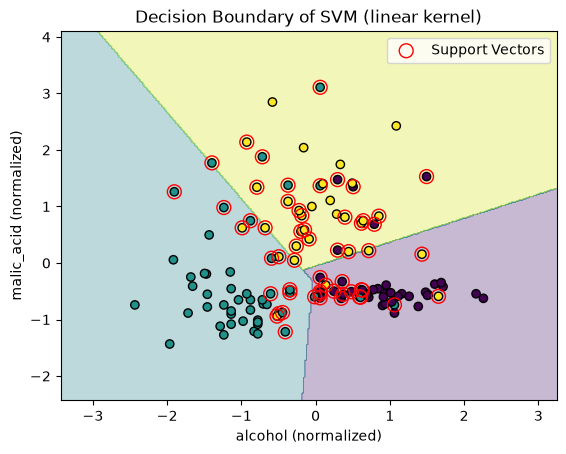

Support vectors per class: [16 18 24]  total: 58


In [25]:
svm_linear = runner(SVC(kernel="linear"), "SVM (linear kernel)")
print("Support vectors per class:", svm_linear.n_support_,
      " total:", svm_linear.n_support_.sum())

### (b) SVM with an RBF (Gaussian) kernel

Classification Report for SVM (RBF kernel):
              precision    recall  f1-score   support

           0       0.87      0.72      0.79        18
           1       0.86      0.86      0.86        21
           2       0.72      0.87      0.79        15

    accuracy                           0.81        54
   macro avg       0.82      0.82      0.81        54
weighted avg       0.82      0.81      0.81        54

Accuracy: 0.8148148148148148
5-fold CV accuracy: 0.809


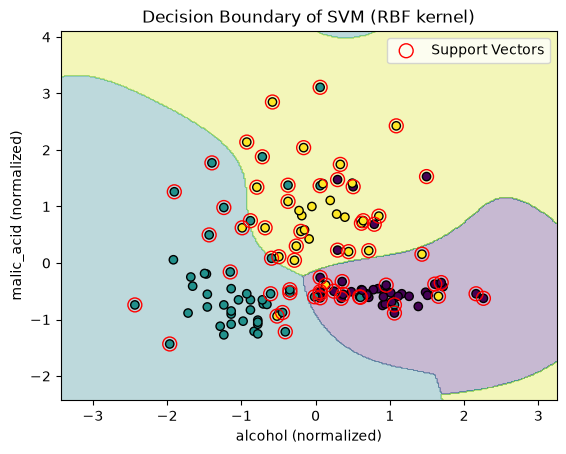

Support vectors per class: [19 21 23]  total: 63


In [26]:
svm_rbf = runner(SVC(kernel="rbf", gamma="scale"), "SVM (RBF kernel)")
print("Support vectors per class:", svm_rbf.n_support_,
      " total:", svm_rbf.n_support_.sum())

### (c) k-NN model

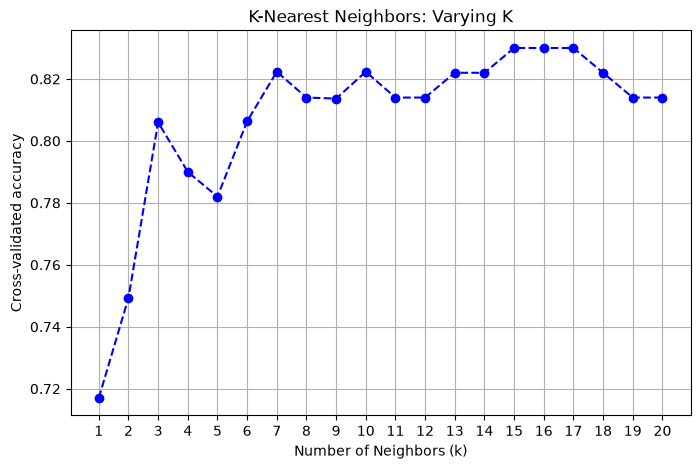

Accuracies for each k: {1: np.float64(0.717), 2: np.float64(0.749), 3: np.float64(0.806), 4: np.float64(0.79), 5: np.float64(0.782), 6: np.float64(0.806), 7: np.float64(0.822), 8: np.float64(0.814), 9: np.float64(0.814), 10: np.float64(0.822), 11: np.float64(0.814), 12: np.float64(0.814), 13: np.float64(0.822), 14: np.float64(0.822), 15: np.float64(0.83), 16: np.float64(0.83), 17: np.float64(0.83), 18: np.float64(0.822), 19: np.float64(0.814), 20: np.float64(0.814)}
Best k: 15


In [27]:
# Try different K
k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    accuracies.append(cross_val_score(knn, X_train, y_train, cv=cv).mean())

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='--', color='b')
plt.title('K-Nearest Neighbors: Varying K')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross-validated accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.grid(True)
plt.show()

best_k = k_values[int(np.argmax(accuracies))]
print("Accuracies for each k:", dict(zip(k_values, np.round(accuracies, 3))))
print("Best k:", best_k)

Classification Report for k-NN (k=15):
              precision    recall  f1-score   support

           0       0.82      0.78      0.80        18
           1       0.82      0.67      0.74        21
           2       0.65      0.87      0.74        15

    accuracy                           0.76        54
   macro avg       0.77      0.77      0.76        54
weighted avg       0.78      0.76      0.76        54

Accuracy: 0.7592592592592593
5-fold CV accuracy: 0.798


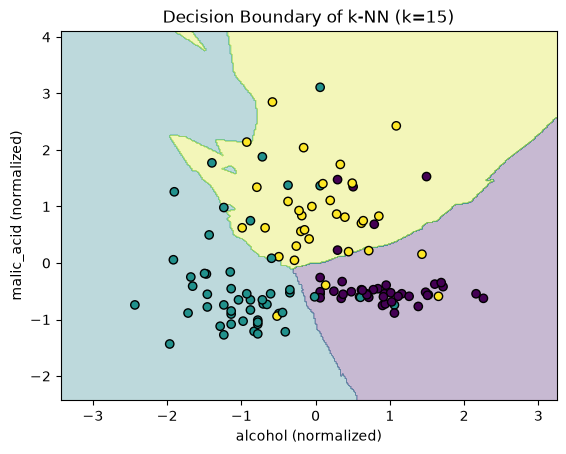

In [28]:
knn = runner(KNeighborsClassifier(n_neighbors=best_k), f"k-NN (k={best_k})", svm=False)

## Step 6: Do the results support my assumptions from Step 4?



The results support most of what I assumed in Step 4, since every decision boundary runs diagonally instead of along one axis, which is what I expected if the two features are complementary, and all three models end up splitting the plane into the same three regions I pointed out. My assumption that the clusters are compact enough for distance based models also holds, because all three models reach roughly 0.76 to 0.82 accuracy using nothing but these two features, and my assumption that the data is only mostly linearly separable holds too, except that the errors concentrate differently from what I guessed, since class 2 ends up with the best recall of 0.87 but the worst precision, somewhere between 0.65 and 0.72.

## Step 7: Equivalence between the models

All three models classify the data well enough to compare, and in terms of performance they are basically the same, with accuracies of 0.778 for the linear SVM, 0.815 for the RBF SVM and 0.759 for k-NN, and cross validation scores that sit even closer together at 0.786, 0.809 and 0.798. Their decision boundaries are equivalent in the same way, because all three carve out the same three regions in the same arrangement and only differ in the shape of the borders, straight for the linear SVM, smoothly curved for the RBF and jagged for k-NN, and the few points they actually disagree on sit in the overlap region where the classes genuinely mix.